# 22. Projeto com o M4 diário: seleção guardada, retomada e custo

**Objetivo e requisitos.** Conduzir um pequeno projeto de previsão com séries reais do M4 diário, do sorteio da amostra à avaliação: preparar a validação temporal, comparar a seleção guardada da AutoHybTS com a escolha pelo menor erro, registrar cada série num banco SQLite (o que permite retomar um projeto interrompido sem refazer o que já terminou) e medir o custo. O projeto usa só o **treino oficial**: os últimos 14 pontos dele ficam selados para a avaliação interna, e o teste oficial não é baixado. Extras `stats` e `plot`; a primeira execução baixa o treino do M4 diário.

In [1]:
import hashlib
import json
import subprocess
import sys
import time
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import autohybts
from autohybts import AutoHybridExperiment, ExperimentStore, load_model, read_manifest, save_model
from autohybts.benchmarks import benchmark_cases
from autohybts.domain.identity import stable_hash
from autohybts.exceptions import ConfigurationError
from autohybts.persistence.manifest import environment, json_safe, source_fingerprint

print("AutoHybTS", autohybts.__version__)

AutoHybTS 1.0.0rc4


## 1. Dados e protocolo

A amostra são 3 séries sorteadas com a semente 0 entre as 4227 do M4 diário; ninguém escolhe as séries à mão. De cada uma usamos só o treino oficial, cortado nos últimos 730 dias para controlar o custo. O horizonte é o do M4 diário, 14 passos, previstos de uma vez (protocolo A); o período de escala do MASE é o do M4 (1).

In [2]:
cases = list(benchmark_cases("m4", "daily", 3, 0, development_only=True, development_tail=730))
H = cases[0].horizon
pd.DataFrame(
    [
        {
            "serie": case.series_id,
            "treino_oficial": case.source["original_train_length"],
            "pontos_usados": len(case.values),
            "inicio": case.values.index[0].date(),
            "fim": case.values.index[-1].date(),
        }
        for case in cases
    ]
).set_index("serie")
assert all(case.source["official_test_accessed"] is False for case in cases)

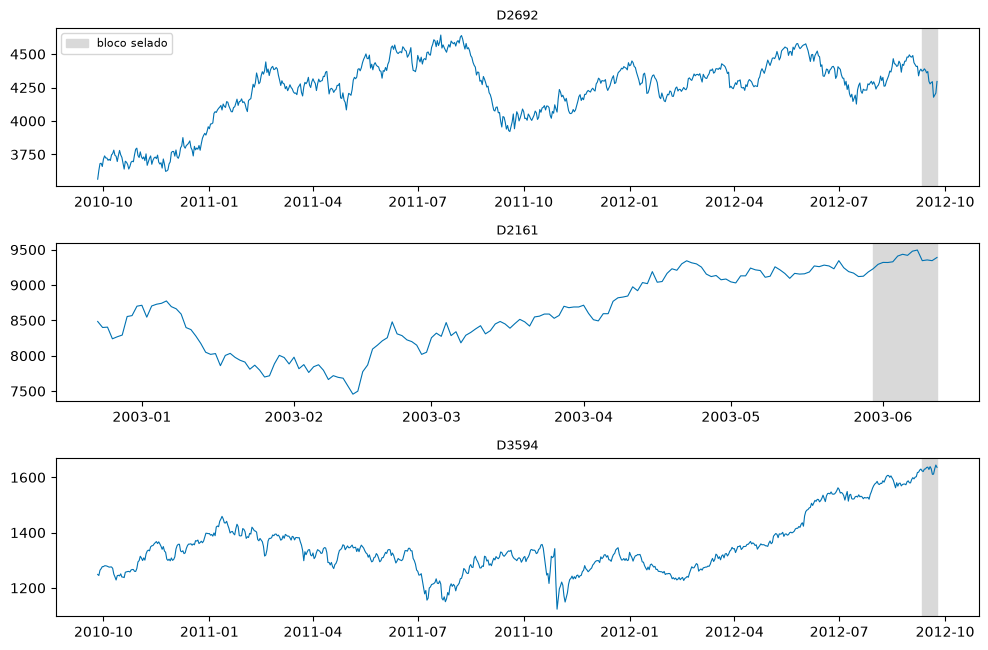

In [3]:
fig, axes = plt.subplots(len(cases), 1, figsize=(10, 2.2 * len(cases)), squeeze=False)
for ax, case in zip(axes.flat, cases, strict=True):
    ax.plot(case.values.index, case.values.to_numpy(), linewidth=0.8, color="#0072B2")
    ax.axvspan(case.values.index[-H], case.values.index[-1], color="0.85", label="bloco selado")
    ax.set_title(case.series_id, fontsize=9)
axes.flat[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 2. Exploração causal

`fit` não busca nada: valida a série, sela os últimos 14 pontos e fixa as origens de `V_search` e `V_select`. A tabela mostra quantas origens cada série comporta por camada (a regra de aceite foi calibrada com 7) e quantas diferenças o ADF e o KPSS, juntos, pedem no trecho de desenvolvimento.

In [4]:
SETTINGS = {
    "fh": H,
    "test_size": H,
    "seasonal_period": cases[0].seasonal_period,
    "session_id": 42,
    "budget": "small",
    "base_models": ["naive", "random_walk_drift", "linear", "exponential_smoothing"],
    "correctors": ["linear", "knn"],
}
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    experiments = {
        case.series_id: AutoHybridExperiment(**SETTINGS).fit(case.values) for case in cases
    }
for message, count in Counter(str(item.message) for item in caught).items():
    print(f"WARNING ({count}): {message}")
pd.DataFrame(
    {
        sid: {
            "development_points": len(exp.history_),
            "origins_per_layer": exp.fold_,
            "suggested_differences": int(exp.stationarity_report()["d_consensus"].iloc[0]),
        }
        for sid, exp in experiments.items()
    }
).T

WARNING (1): fold='auto': o histórico comporta 4 origem(ns) por camada, menos que as 7 da calibração da regra de aceite; com menos unidades a regra aceita estruturas espúrias com mais frequência.


,development_points,origins_per_layer,suggested_differences
D2692,716,7,1
D2161,158,4,1
D3594,716,7,1


## 3. Controles e modelos propostos

A mesma busca (persistência, passeio aleatório com tendência, regressão linear, suavização exponencial e correções residuais linear e KNN) alimenta três escolhas:

- **seleção guardada** (`compare_models().best`): só aceita complexidade que passa na regra de aceite;
- **menor erro**: a finalista de menor MASE em `V_select`, sem limiar;
- **persistência**: o controle mais simples.

Cada série vira uma execução no banco `artifacts/m4_project/m4.db`. A pasta é preservada: reexecutar o notebook reutiliza casos compatíveis. Dados, parâmetros, ambiente e fontes da biblioteca entram na identidade; mudanças exigem outra pasta. A versão do fluxo fica explícita no esquema. Execute um único processo escritor por pasta.

Um caso só é registrado depois de buscar, avaliar as escolhas distintas e salvar seus modelos. Os artefatos são criados por esta execução; por isso o carregamento abaixo declara confiança explicitamente. A equivalência das previsões é conferida antes do registro. Se houver interrupção antes dele, esse caso será refeito; casos já registrados permanecem intactos.

In [5]:
folder = Path("artifacts/m4_project")
store = ExperimentStore(folder / "m4.db")
identity = {
    "schema": "m4-project/3",
    "settings": SETTINGS,
    "data": {
        case.series_id: hashlib.sha256(
            pd.util.hash_pandas_object(case.values, index=True).to_numpy().tobytes()
        ).hexdigest()
        for case in cases
    },
    "source": source_fingerprint(),
    "environment": {key: value for key, value in environment().items() if key != "git_commit"},
}
project_id = stable_hash(json_safe(identity))


def verify_saved(tags):
    """Check saved models against forecasts already in SQLite, without reading targets again."""
    predictions = store.query("SELECT model_id, timestamp, y_pred FROM predictions")
    for choice in {item["model_id"]: item for item in tags["choices"].values()}.values():
        model = load_model(folder / choice["artifact"], trusted=True, sha256=choice["sha256"])
        recorded = predictions[predictions.model_id == choice["model_id"]].sort_values("timestamp")
        if len(recorded) != H:
            raise ConfigurationError("Incomplete saved forecasts; restore the project artifacts.")
        np.testing.assert_allclose(model.predict(H).y_pred, recorded.y_pred, rtol=1e-12, atol=1e-12)


def run_project():
    """Persist evaluated cases and reuse compatible complete results."""
    saved = (
        store.query("SELECT name, tags FROM runs")
        if store.path.is_file()
        else pd.DataFrame(columns=["name", "tags"])
    )
    completed = {}
    for row in saved.itertuples():
        tags = json.loads(row.tags)
        if tags.get("project_id") != project_id:
            raise ConfigurationError("Incompatible project: use a different output directory.")
        verify_saved(tags)
        completed[row.name] = tags
    new = []
    for sid, exp in experiments.items():
        if sid in completed:
            continue
        started = time.perf_counter()
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            result = exp.compare_models()
            search_seconds = time.perf_counter() - started
            lowest_id = result.selection_leaderboard.MASE.idxmin()
            lowest = next(
                r.candidate for r in result.selection.finalists if r.candidate_id == lowest_id
            )
            picks = {
                "guarded": result.best,
                "lowest_error": lowest,
                "persistence": exp.create_model("naive").candidate,
            }
            models, choices = {}, {}
            for label, spec in picks.items():
                if spec.candidate_id not in models:
                    model = exp.finalize_model(spec)
                    exp.evaluate_external(model)
                    relative = Path("models") / sid / model.model_id
                    save_model(model, folder / relative)
                    restored = load_model(folder / relative, trusted=True)
                    pd.testing.assert_frame_equal(model.predict(H), restored.predict(H))
                    models[spec.candidate_id] = model
                model = models[spec.candidate_id]
                relative = Path("models") / sid / model.model_id
                choices[label] = {
                    "model_id": model.model_id,
                    "artifact": relative.as_posix(),
                    "sha256": read_manifest(folder / relative)["payload"]["sha256"],
                }
        messages = Counter(str(item.message) for item in caught)
        for message, count in messages.items():
            print(f"WARNING ({count}): {message}")
        tags = {
            "project_id": project_id,
            "identity": identity,
            "choices": choices,
            "search_seconds": search_seconds,
            "case_seconds": time.perf_counter() - started,
            "warnings": dict(messages),
        }
        store.log(exp, name=sid, tags=tags, models=list(models.values()), values=True)
        verify_saved(tags)
        new.append(sid)
    return new

## 4. Busca e seleção

A primeira chamada executa somente as séries ainda não concluídas. A segunda verifica que os registros não mudam. Ao executar novamente após reiniciar o kernel, a mesma função consulta o banco, confere identidade e artefatos e reutiliza os casos completos. As etapas seguintes leem tabelas persistidas, sem depender dos objetos de resultado da busca. Avisos são exibidos e registrados; não são descartados.

In [6]:
print("New cases:", run_project())
before = store.query("SELECT run_id, logged_utc FROM runs ORDER BY run_id")
assert run_project() == []
pd.testing.assert_frame_equal(
    before, store.query("SELECT run_id, logged_utc FROM runs ORDER BY run_id")
)
print("Resume: no new cases; database records unchanged.")
saved_runs = store.query("SELECT name, tags FROM runs ORDER BY name")
pd.DataFrame(
    [
        {
            "series": row.name,
            **{key: json.loads(row.tags)[key] for key in ("search_seconds", "case_seconds")},
        }
        for row in saved_runs.itertuples()
    ]
).set_index("series").round(2)

New cases: ['D2692', 'D2161', 'D3594']
Resume: no new cases; database records unchanged.


,search_seconds,case_seconds
series,,
D2161,3.54,3.75
D2692,26.18,26.71
D3594,21.46,21.65


## 5. Resultados e gráficos

O banco responde quem venceu em cada série e por quê: cada desafiante comparado com o campeão da vez, com ganho mediano, taxa de vitórias e motivo.

In [7]:
store.query(
    """
    SELECT r.name AS serie, d.family, d.challenger_label AS desafiante, d.accepted AS aceito,
           ROUND(d.median_gain, 3) AS ganho_mediano, ROUND(d.win_rate, 2) AS vitorias,
           d.reason_codes AS motivos
    FROM decisions d JOIN runs r USING (run_id)
    ORDER BY r.name, d.step
    """
)

,serie,family,desafiante,aceito,ganho_mediano,vitorias,motivos
0,D2161,linear,linear(lags=7),0,-0.639,0.00,"[""median_gain_below_threshold"", ""win_rate_belo..."
1,D2161,residual,"naive + linear [w=7, alpha=0.5, historical_oof...",0,0.037,1.00,"[""median_gain_below_threshold""]"
2,D2692,linear,linear(lags=7),0,0.064,0.57,"[""win_rate_below_threshold""]"
3,D2692,residual,"random_walk_drift + linear [w=7, alpha=0.5, hi...",0,-0.008,0.29,"[""median_gain_below_threshold"", ""win_rate_belo..."
4,D3594,linear,linear(lags=7),0,-0.184,0.29,"[""median_gain_below_threshold"", ""win_rate_belo..."
5,D3594,residual,"random_walk_drift + linear [w=7, alpha=1.0, hi...",0,-0.002,0.43,"[""median_gain_below_threshold"", ""win_rate_belo..."


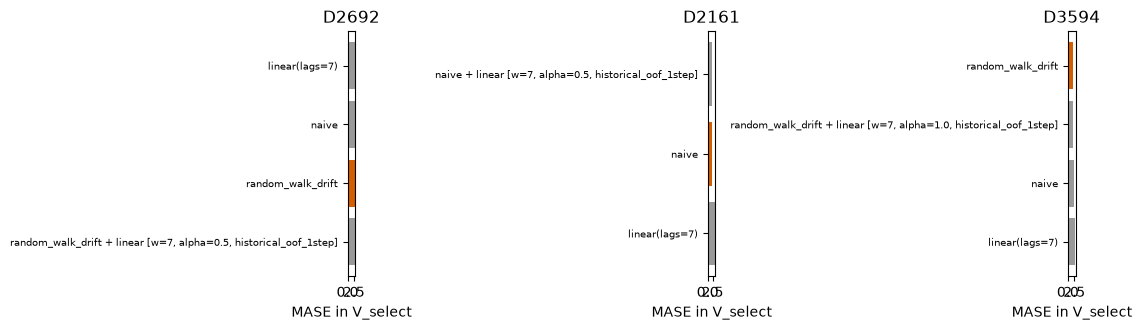

In [8]:
board = store.query(
    """
    SELECT r.name AS series, c.label, m.value AS MASE, e.is_champion
    FROM metrics m JOIN runs r USING (run_id)
    JOIN candidates c USING (run_id, candidate_id)
    JOIN evaluations e USING (run_id, candidate_id, layer)
    WHERE m.layer = 'select' AND m.metric = 'MASE'
    ORDER BY r.name, m.value
    """
)
fig, axes = plt.subplots(1, len(cases), figsize=(11, 3.4), squeeze=False)
for ax, case in zip(axes.flat, cases, strict=True):
    part = board[board.series == case.series_id]
    ax.barh(
        part.label, part.MASE, color=["#D55E00" if value else "0.6" for value in part.is_champion]
    )
    ax.invert_yaxis()
    ax.set(title=case.series_id, xlabel="MASE in V_select")
    ax.tick_params(axis="y", labelsize=7)
fig.tight_layout()
plt.show()

## 6. Diagnóstico e limites

Uma série curta comporta menos origens que as 7 da calibração da regra de aceite; com menos unidades, a regra aceita estruturas espúrias com mais frequência, e o experimento avisa. Três séries, uma semente e o orçamento `small` dimensionam o projeto, mas não sustentam conclusões sobre o M4 inteiro.

In [9]:
store.query(
    """
    SELECT r.name AS serie, r.n_origins AS origens_duas_camadas, COUNT(l.seq) AS propostas,
           SUM(l.status = 'EVALUATED') AS avaliadas, ROUND(SUM(l.seconds), 1) AS segundos_busca
    FROM runs r JOIN ledger l USING (run_id)
    GROUP BY r.name ORDER BY r.name
    """
)

,serie,origens_duas_camadas,propostas,avaliadas,segundos_busca
0,D2161,8,32,17,3.1
1,D2692,14,32,17,25.0
2,D3594,14,32,17,20.6


## 7. Avaliação interna e custo

Cada escolha distinta foi reajustada e avaliada uma única vez no bloco interno durante `run_project`, antes do registro final do caso. Aqui lemos métricas e previsões do SQLite; não reabrimos o bloco reservado. A tabela é exportada em CSV. `search_seconds` mede busca/seleção; `case_seconds` inclui também finalização, avaliação e persistência. Custos compartilhados não são somados entre escolhas.

In [10]:
rows, paths = [], {}
external = store.query(
    "SELECT run_id, model_id, value FROM external WHERE metric = 'MASE' AND series_id IS NOT NULL"
)
predictions = store.query(
    "SELECT model_id, timestamp, y_pred, y_true FROM predictions ORDER BY timestamp"
)
for run in store.query("SELECT run_id, name, tags FROM runs ORDER BY name").itertuples():
    for label, choice in json.loads(run.tags)["choices"].items():
        score = external[
            (external.run_id == run.run_id) & (external.model_id == choice["model_id"])
        ]
        if len(score) != 1:
            raise ConfigurationError("Missing or ambiguous saved evaluation.")
        rows.append({"series": run.name, "choice": label, "MASE": score.value.iloc[0]})
        path = predictions[predictions.model_id == choice["model_id"]].copy()
        path["timestamp"] = pd.to_datetime(path.timestamp)
        paths[run.name, label] = path.set_index("timestamp")
internal = pd.DataFrame(rows)
internal.to_csv(folder / "internal_metrics.csv", index=False)
internal.pivot(index="series", columns="choice", values="MASE").round(3)

choice,guarded,lowest_error,persistence
series,,,
D2161,2.591,2.509,2.591
D2692,3.366,2.724,3.058
D3594,0.836,0.836,0.791


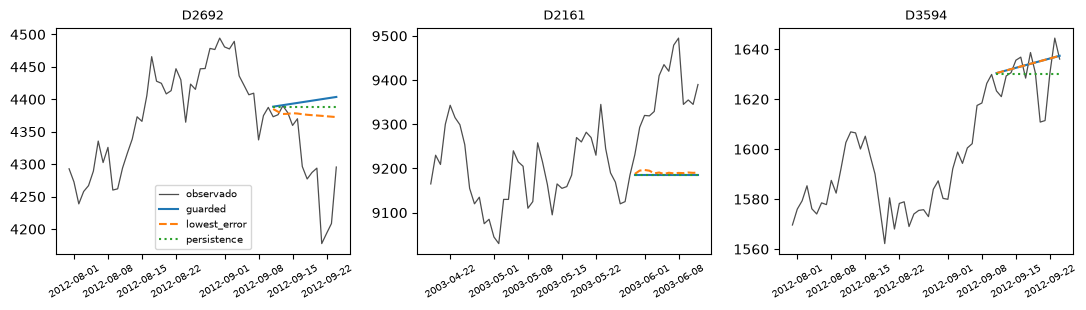

In [11]:
fig, axes = plt.subplots(1, len(cases), figsize=(11, 3.2), squeeze=False)
for ax, case in zip(axes.flat, cases, strict=True):
    sid = case.series_id
    recent = case.values.iloc[-4 * H :]
    ax.plot(recent.index, recent.to_numpy(), color="0.3", linewidth=0.9, label="observado")
    for label, style in (("guarded", "-"), ("lowest_error", "--"), ("persistence", ":")):
        table = paths[sid, label]
        ax.plot(table.index, table["y_pred"], linestyle=style, label=label)
    ax.set_title(sid, fontsize=9)
    ax.tick_params(axis="x", labelrotation=30, labelsize=7)
axes.flat[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

### Verificação em outro processo

Um novo interpretador abre o banco e carrega os modelos salvos, sem objetos desta sessão. As previsões são comparadas às já registradas, sem nova leitura dos alvos.

In [12]:
verification = """
import json
import sys
from pathlib import Path
import numpy as np
from autohybts import ExperimentStore, load_model
folder = Path(sys.argv[1])
store = ExperimentStore(folder / 'm4.db')
runs = store.query('SELECT tags FROM runs')
predictions = store.query('SELECT model_id, timestamp, y_pred FROM predictions ORDER BY timestamp')
checked = set()
for row in runs.itertuples():
    for choice in json.loads(row.tags)['choices'].values():
        if choice['model_id'] in checked:
            continue
        model = load_model(folder / choice['artifact'], trusted=True, sha256=choice['sha256'])
        recorded = predictions[predictions.model_id == choice['model_id']]
        np.testing.assert_allclose(
            model.predict(len(recorded)).y_pred, recorded.y_pred, rtol=1e-12, atol=1e-12
        )
        checked.add(choice['model_id'])
print(f'Independent process: {len(runs)} cases and {len(checked)} models verified.')
"""
verified = subprocess.run(
    [sys.executable, "-c", verification, str(folder.resolve())],
    check=True,
    capture_output=True,
    text=True,
)
print(verified.stdout.strip())

Independent process: 3 cases and 7 models verified.


## 8. Leitura

- **Dados.** O sorteio trouxe D2692, D2161 e D3594. A D2161 tem só 172 dias de treino oficial: comporta 4 origens por camada, menos que as 7 da calibração, e o experimento avisou. Nas três séries, o ADF e o KPSS pedem uma diferença.
- **Seleção guardada.** Ficou com um modelo individual nas três: persistência na D2161 e passeio aleatório com tendência nas outras duas. Nenhum desafiante passou na regra de aceite, por motivos diferentes. Na D2161, o híbrido persistência + corretor linear venceu nas 4 unidades, mas com ganho mediano de 3,7 %, abaixo dos 5 %. Na D2692, a regressão linear teve ganho de 6,4 %, mas só 57 % de vitórias, abaixo dos 60 %.
- **Menor erro.** Escolheria esse híbrido na D2161 e a regressão linear na D2692. No bloco selado de 14 dias, essas escolhas tiveram MASE menor que a seleção guardada: 2,51 contra 2,59 e 2,72 contra 3,37. Na D3594 as duas escolheram o mesmo modelo, e a persistência foi a melhor (0,79 contra 0,84).
- **Como ler isso.** Nesta amostra, a cautela da regra não se pagou: as candidatas que ela recusou estavam perto do limiar e acertaram no bloco interno. Mas cada série teve uma única janela de 14 dias, e três séries não sustentam uma comparação. A regra foi calibrada para errar pouco por excesso de complexidade em muitas séries, não para vencer em cada uma. Um estudo com mais séries e sementes é o que decide se ela é conservadora demais no M4 diário.
- **Retomada e custo.** A busca/seleção somou 51.2 s e os casos, incluindo finalização, avaliação e persistência, 52.1 s nesta execução. A segunda chamada não criou casos nem alterou os registros. Outro processo carregou os modelos e reproduziu as previsões salvas; ao reexecutar o notebook, as tabelas são reconstruídas do banco. Esses tempos dependem da máquina e dos caches. Um caso interrompido antes do registro final será refeito; os demais são preservados.